# Figures_Tables_Doublespeak_CMT

Produces the figures and tables in the manuscript on doublespeak around CMTs.

Author: Charlotte Sophia Bez

Date: 23 Nov 2026


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

In [2]:
def find_cssn_projects_root(start=None):
    """Return the nearest 'CSSN_Projects' folder on the current path."""
    start = Path.cwd() if start is None else Path(start).resolve()
    for candidate in (start, *start.parents):
        if candidate.name == 'CSSN_Projects':
            return candidate
    raise FileNotFoundError(
        "Could not find a 'CSSN_Projects' folder in the current path. "
        "Run the notebook from inside CSSN_Projects (or one of its subfolders)."
    )

PROJECT_ROOT = find_cssn_projects_root()

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / 'Publication_CSSN_LLM.ipynb').exists():
    NOTEBOOK_DIR = PROJECT_ROOT / '03_Analysis' / 'NCC_Bez_Franta_Klug'
DATA_DIR = NOTEBOOK_DIR

input_path = DATA_DIR / 'combined_manual_clara_reviewed_19.11.xlsx'
combined_df = pd.read_excel(input_path, sheet_name='Combined Data')

print(f"Loaded combined_df: {len(combined_df)} rows from {input_path}")

Loaded combined_df: 430 rows from c:\Users\charlotte\Dropbox\CSSN_Projects\03_Analysis\NCC_Bez_Franta_Klug\combined_manual_clara_reviewed_19.11.xlsx


In [3]:
before = len(combined_df)
combined_df = combined_df[combined_df['statement_category'] != 0].copy()
print(f"Dropped {before - len(combined_df)} rows with no statement category (value 0)")

combined_df['statement_category'] = (
    combined_df['statement_category']
    .astype(str)
    .str.replace(r'\bno champions\b', 'lack of champions', regex=True)
)

NON_CORPORATE_ACTORS = ['CMI', 'RFF', 'Columbia', 'National Biodiesel Board']
before = len(combined_df)
combined_df = combined_df[~combined_df['company'].isin(NON_CORPORATE_ACTORS)].copy()
print(f"Dropped {before - len(combined_df)} rows from non-corporate actors: {NON_CORPORATE_ACTORS}")

print(f"combined_df after cleaning: {len(combined_df)} rows")

combined_df['Document ID_clean'] = combined_df['Document ID_clean'].astype(str).str.strip().str.upper()

year_lookup = (
    combined_df[combined_df['Document ID_clean'].notna()
                & (combined_df['Document ID_clean'] != 'NAN')]
    .dropna(subset=['year'])
    .drop_duplicates(subset='Document ID_clean', keep='first')
    [['Document ID_clean', 'year']]
)

manual_years = {
    'API_10': 2019,
    'API_45': 2018,
    'BP_14': 2019,
    'BP_22': 2019,
    'EXXONMOBIL_SEPT_20': 2016,
    'EXXONMOBIL_SEPT_11': 2016,  # carried over from reviewed_16.09
    'EM-HCOR3-00151405': np.nan,
    'EM-HCOR3-00604560': 2010,
    'SHELL_1': 2019,
    'EM-HCOR3-00005564': 2018,
}
manual_lookup = pd.DataFrame([
    {'Document ID_clean': k, 'year': v} for k, v in manual_years.items()
])

year_lookup = pd.concat([manual_lookup, year_lookup], ignore_index=True)
year_lookup = year_lookup.drop_duplicates(subset='Document ID_clean', keep='first')

before = combined_df['year'].isna().sum()
combined_df = combined_df.merge(year_lookup, on='Document ID_clean', how='left', suffixes=('', '_lookup'))
combined_df['year'] = combined_df['year'].fillna(combined_df['year_lookup'])
combined_df = combined_df.drop(columns=['year_lookup'])
print(f"Filled {before - combined_df['year'].isna().sum()} missing years; {combined_df['year'].isna().sum()} still missing")


Dropped 88 rows with no statement category (value 0)
Dropped 9 rows from non-corporate actors: ['CMI', 'RFF', 'Columbia', 'National Biodiesel Board']
combined_df after cleaning: 333 rows
Filled 3 missing years; 147 still missing


In [4]:
MISSING_YEARS_PATH = DATA_DIR / 'combined_manual_clara_04.09_missing_years.xlsx'
missing_years_df = pd.read_excel(MISSING_YEARS_PATH, sheet_name='Sheet1')

missing_years_df['Document ID_lookup'] = missing_years_df['doc_id'].astype(str).str.strip().str.upper()

# reviewed documents where no year could be established, keep a record
# so the fallback below does not back fill them from unsupported metadata
undetermined_ids = set(
    missing_years_df.loc[missing_years_df['year'].isna(), 'Document ID_lookup']
)

missing_years_df = (missing_years_df.dropna(subset=['year'])
                    .drop_duplicates(subset='Document ID_lookup', keep='first'))

combined_df['Document ID_lookup'] = combined_df['Document ID'].astype(str).str.strip().str.upper()

before = combined_df['year'].isna().sum()
combined_df = combined_df.merge(
    missing_years_df[['Document ID_lookup', 'year']],
    on='Document ID_lookup', how='left', suffixes=('', '_manual')
)
combined_df['year'] = combined_df['year'].fillna(combined_df['year_manual'])
combined_df = combined_df.drop(columns=['year_manual'])

after_manual = combined_df['year'].isna().sum()
print(f"Filled {before - after_manual} missing years from {MISSING_YEARS_PATH}; "
      f"{after_manual} still missing")

fallback_lookup = (
    combined_df[combined_df['Document ID_lookup'].notna()
                & ~combined_df['Document ID_lookup'].isin(['NAN', ''])
                & ~combined_df['Document ID_lookup'].isin(undetermined_ids)]
    .dropna(subset=['year'])
    .drop_duplicates(subset='Document ID_lookup', keep='first')
    [['Document ID_lookup', 'year']]
)

combined_df = combined_df.merge(fallback_lookup, on='Document ID_lookup',
                                how='left', suffixes=('', '_fallback'))
combined_df['year'] = combined_df['year'].fillna(combined_df['year_fallback'])
combined_df = combined_df.drop(columns=['year_fallback', 'Document ID_lookup'])

after = combined_df['year'].isna().sum()
print(f"Filled {after_manual - after} further missing years from other rows of the "
      f"same document; {after} still missing")
if after:
    still_missing = (combined_df.loc[combined_df['year'].isna(), 'Document ID']
                     .astype(str).str.strip().str.upper().unique())
    print("  Documents still without a year:", ', '.join(sorted(still_missing)))


Filled 144 missing years from c:\Users\charlotte\Dropbox\CSSN_Projects\03_Analysis\NCC_Bez_Franta_Klug\combined_manual_clara_04.09_missing_years.xlsx; 3 still missing


Filled 1 further missing years from other rows of the same document; 2 still missing
  Documents still without a year: BPA_HCOR_00205494, EM-HCOR3-00151405


In [5]:
# independent internal vs external label per document,
# used later to weight statements by audience
DOC_TYPE_PATH = DATA_DIR / 'clara_doc_type_classifications_14.09.xlsx'
doc_type_df = pd.read_excel(DOC_TYPE_PATH, sheet_name='Sheet1')
doc_type_df['Document ID_clean'] = doc_type_df['doc_id'].astype(str).str.strip().str.upper()

def normalize_audience(value):
    value = str(value).strip().lower()
    if value.startswith('internal'):
        return 'internal'
    if value.startswith('external'):
        return 'external'
    return 'DROP'

doc_type_df['audience_clean'] = doc_type_df['audience'].apply(normalize_audience)

print(f"Loaded doc_type_df: {len(doc_type_df)} rows, "
      f"{doc_type_df['Document ID_clean'].nunique()} distinct Document IDs")
print()
print("Raw 'audience' values:")
print(doc_type_df['audience'].value_counts(dropna=False).to_string())

n_drop = (doc_type_df['audience_clean'] == 'DROP').sum()
doc_type_df = doc_type_df[doc_type_df['audience_clean'] != 'DROP'].copy()
print(f"\nRemoved {n_drop} rows classified as DROP")

conflicting = doc_type_df.groupby('Document ID_clean')['audience_clean'].nunique()
conflicting_ids = conflicting[conflicting > 1].index
if len(conflicting_ids):
    print(f"Warning: {len(conflicting_ids)} Document IDs have conflicting audience "
          f"labels across duplicate rows (keeping the first): {sorted(conflicting_ids)}")

before = len(doc_type_df)
doc_type_df = doc_type_df.drop_duplicates(subset='Document ID_clean', keep='first')
print(f"Dropped {before - len(doc_type_df)} duplicate-Document-ID rows "
      f"({len(doc_type_df)} rows remain, {doc_type_df['Document ID_clean'].nunique()} distinct)")

print()
print("Final audience distribution (internal / external):")
print(doc_type_df['audience_clean'].value_counts().to_string())


Loaded doc_type_df: 698 rows, 557 distinct Document IDs

Raw 'audience' values:
audience
internal     454
external     168
DROP          58
internal      14
external       4

Removed 58 rows classified as DROP
Dropped 136 duplicate-Document-ID rows (504 rows remain, 504 distinct)

Final audience distribution (internal / external):
audience_clean
internal    375
external    129


In [6]:
base_df = combined_df.dropna(subset=['statement_category', 'statement_class', 'year']).copy()

print(f"Base_df: {len(base_df)} rows")
print(f"  Skeptical: {(base_df['statement_class']=='skeptical').sum()}")
print(f"  Confident: {(base_df['statement_class']=='confident').sum()}")

base_df['technology'] = base_df['technology'].astype(str).str.strip().str.lower()
base_df['umbrella_list'] = base_df['technology'].str.split(r'\s*,\s*')
base_df['statement_category'] = base_df['statement_category'].astype(str).str.strip()
base_df['category_list'] = base_df['statement_category'].str.split(r'\s*,\s*')

exploded_all_df = base_df.explode('umbrella_list').explode('category_list')

exploded_all_df['umbrella_list'] = exploded_all_df['umbrella_list'].str.strip()
exploded_all_df['statement_category'] = exploded_all_df['category_list'].str.strip()

umbrella_display = {'ccus': 'CCUS', 'biofuels': 'Biofuels', 'hydrogen': 'Hydrogen'}
exploded_all_df['umbrella'] = exploded_all_df['umbrella_list'].map(umbrella_display)

unmapped = exploded_all_df[exploded_all_df['umbrella'].isna()]['umbrella_list'].unique()
if len(unmapped):
    print("Warning: unmapped technology values:", unmapped)

exploded_all_df = exploded_all_df.dropna(subset=['umbrella'])

exploded_all_df = exploded_all_df[exploded_all_df['year'] != 2022].copy()

print(f"Exploded_all_df: {len(exploded_all_df)} rows")

n_relevant_statements = exploded_all_df.index.nunique()
n_relevant_documents = (base_df.loc[exploded_all_df.index.unique(), 'Document ID']
                        .astype(str).str.strip().str.upper().nunique())
print(f"We code {n_relevant_statements} relevant statements across {n_relevant_documents} "
      f"distinct documents that describe corporate positioning on carbon capture, "
      f"utilisation, and storage (CCUS), hydrogen, and biofuels.")

viable_args = {
    'confident': ['cost effective', 'tech proven', 'fuel of the future', 'fits business model'],
    'skeptical': ['economically challenging', 'economically inviable', 'infrastructure challenges',
                  'technically challenging', 'technically unproven', 'less efficient than alternatives']
}

strategic_args = {
    'confident': ['climate positive', 'economic benefits', 'ensures fossil future', 'nationalist',
                  'role in sectoral transitions', 'tech champions'],
    'skeptical': ['downplaying', 'lack of champions']
}

categories = ['CCUS', 'Hydrogen', 'Biofuels']


Base_df: 330 rows
  Skeptical: 113
  Confident: 217
Exploded_all_df: 451 rows
We code 330 relevant statements across 107 distinct documents that describe corporate positioning on carbon capture, utilisation, and storage (CCUS), hydrogen, and biofuels.


In [7]:

CATEGORY_ALIASES = {
    'infrastructure constraints': 'infrastructure challenges',  # same argument just spelled differently
}
# categories not in viable_args / strategic_args above
EXTRA_STRATEGIC = {'skeptical': ['environmental integrity']}    # environmental integrity doubts
                                                                # are framed not viability claims

bar_df = exploded_all_df.copy()
bar_df['statement_category'] = (bar_df['statement_category']
                                .replace(CATEGORY_ALIASES))

arg_type_map = {}
for cls in ['confident', 'skeptical']:
    for cat in viable_args[cls]:
        arg_type_map[(cls, cat)] = 'viability'
    for cat in list(strategic_args[cls]) + EXTRA_STRATEGIC.get(cls, []):
        arg_type_map[(cls, cat)] = 'strategic'

bar_df['arg_type'] = [arg_type_map.get((c, s))
                      for c, s in zip(bar_df['statement_class'], bar_df['statement_category'])]

unclassified = bar_df.loc[bar_df['arg_type'].isna(), ['statement_class', 'statement_category']]
if len(unclassified):
    print('Warning: dropped statements with no argument type:')
    print(unclassified.value_counts())
bar_df = bar_df.dropna(subset=['arg_type'])
bar_df['year'] = bar_df['year'].astype(int)

INK, INK_MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'

def ramp_colors(cmap_name, n):
    """Ordinal ramp: darkest step for the most frequent category."""
    return [plt.get_cmap(cmap_name)(v) for v in np.linspace(0.92, 0.38, max(n, 1))]

rc = {
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'savefig.facecolor': 'white', 'figure.facecolor': 'white',
}


statement_class  statement_category
confident        technically proven    5
                 nationalism           2
Name: count, dtype: int64


In [8]:
CLASS_COLUMNS = ['skeptical', 'confident']
ARG_CMAP = {'strategic': 'Blues', 'viability': 'Reds'}

THEME_CATEGORIES = {
    'Climate and environmental aspects': [
        'climate positive', 'role in sectoral transitions', 'fuel of the future',
        'environmental integrity', 'less efficient than alternatives',
    ],
    'Economic characteristics': [
        'cost effective', 'economic benefits', 'nationalist',
        'economically challenging', 'economically inviable',
    ],
    'Business model compatibility': [
        'ensures fossil future', 'fits business model', 'tech champions',
        'lack of champions', 'infrastructure challenges', 'downplaying',
    ],
    'Technical aspects': [
        'tech proven', 'technically challenging', 'technically unproven',
    ],
}
CATEGORY_TO_THEME = {cat: theme for theme, cats in THEME_CATEGORIES.items() for cat in cats}
THEME_MARKER = {
    'Climate and environmental aspects': 'o',
    'Economic characteristics': 'D',
    'Business model compatibility': 's',
    'Technical aspects': '^',
}


In [9]:

base_df_ny = combined_df.dropna(subset=['statement_category', 'statement_class']).copy()
base_df_ny['year'] = base_df_ny['year'].apply(lambda y: 'n.a.' if pd.isna(y) else y)

base_df_ny['technology'] = base_df_ny['technology'].astype(str).str.strip().str.lower()
base_df_ny['umbrella_list'] = base_df_ny['technology'].str.split(r'\s*,\s*')
base_df_ny['statement_category'] = base_df_ny['statement_category'].astype(str).str.strip()
base_df_ny['category_list'] = base_df_ny['statement_category'].str.split(r'\s*,\s*')

exploded_all_df_ny = base_df_ny.explode('umbrella_list').explode('category_list')
exploded_all_df_ny['umbrella_list'] = exploded_all_df_ny['umbrella_list'].str.strip()
exploded_all_df_ny['statement_category'] = exploded_all_df_ny['category_list'].str.strip()

exploded_all_df_ny['umbrella'] = exploded_all_df_ny['umbrella_list'].map(umbrella_display)
exploded_all_df_ny = exploded_all_df_ny.dropna(subset=['umbrella'])

exploded_all_df_ny = exploded_all_df_ny[exploded_all_df_ny['year'] != 2022].copy()

n_no_year = (exploded_all_df_ny['year'] == 'n.a.').sum()
n_no_year_docs = (exploded_all_df_ny.loc[exploded_all_df_ny['year'] == 'n.a.', 'Document ID']
                   .astype(str).str.strip().str.upper().nunique())
print(f"Exploded_all_df_ny: {len(exploded_all_df_ny)} rows "
      f"({n_no_year} with n.a., across {n_no_year_docs} documents, "
      f"audience: {sorted(exploded_all_df_ny.loc[exploded_all_df_ny['year'] == 'n.a.', 'audience'].unique())})")


Exploded_all_df_ny: 455 rows (4 with n.a., across 2 documents, audience: ['external'])


In [10]:
bar_df_ny = exploded_all_df_ny.copy()
bar_df_ny['statement_category'] = (bar_df_ny['statement_category']
                                   .replace(CATEGORY_ALIASES))

bar_df_ny['arg_type'] = [arg_type_map.get((c, s))
                         for c, s in zip(bar_df_ny['statement_class'], bar_df_ny['statement_category'])]
bar_df_ny = bar_df_ny.dropna(subset=['arg_type'])

def year_sort_key_ny(y):
    return (1, 0) if y == 'n.a.' else (0, y)


In [11]:
cat_order_ny = {}
for stmt_class in CLASS_COLUMNS:
    for arg_type, cmap_name in ARG_CMAP.items():
        cats = (bar_df_ny[(bar_df_ny['statement_class'] == stmt_class)
                       & (bar_df_ny['arg_type'] == arg_type)]['statement_category']
                .value_counts().index.tolist())
        cat_order_ny[(stmt_class, arg_type)] = cats

swap_key = ('skeptical', 'viability')
swap_order = cat_order_ny[swap_key]
if 'technically unproven' in swap_order and 'infrastructure challenges' in swap_order:
    i, j = swap_order.index('technically unproven'), swap_order.index('infrastructure challenges')
    swap_order[i], swap_order[j] = swap_order[j], swap_order[i]


In [12]:
dedup_doc_type = doc_type_df


def write_latex_tables(path, tables):
    """Write one or more DataFrames as LaTeX table floats to a single .tex file."""
    index_labels = {'company': 'Company', 'umbrella': 'Technology',
                    'doc_type': 'Document type'}
    with open(path, 'w', encoding='utf-8') as f:
        for caption, label, table in tables:
            tex_df = table.reset_index()
            first_col = tex_df.columns[0]
            tex_df = tex_df.rename(
                columns={first_col: index_labels.get(first_col, first_col)})
            f.write(tex_df.to_latex(index=False, caption=caption, label=label,
                                    float_format='%.1f', escape=True, na_rep=''))
            f.write('\n')
    print(f"Saved: {path}")


doc_type_tables = {}
for audience in ['internal', 'external']:
    sub = dedup_doc_type[dedup_doc_type['audience_clean'] == audience]
    counts = sub['doc_type'].value_counts(dropna=False)
    share = (100 * counts / len(sub)).round(1)
    table = pd.DataFrame({'n': counts, 'share_%': share})
    print(f"--- Document type distribution: {audience} (n={len(sub)} documents) ---")
    print(table.to_string())
    print()
    doc_type_tables[audience] = table

DOC_TYPE_TEX_PATH = 'doc_type_distribution.tex'
write_latex_tables(DOC_TYPE_TEX_PATH, [
    (f'Document type distribution: {aud}', f'tab:doc-type-{aud}', doc_type_tables[aud])
    for aud in ['internal', 'external']
])


--- Document type distribution: internal (n=375 documents) ---
                             n  share_%
doc_type                               
email conversation only    102     27.2
executive briefing          72     19.2
committee meeting agenda    66     17.6
internal strategy           35      9.3
committee meeting slides    31      8.3
NaN                         20      5.3
newsletter                  16      4.3
partner strategy document   14      3.7
committee meeting report    11      2.9
communications study         8      2.1

--- Document type distribution: external (n=129 documents) ---
                              n  share_%
doc_type                                
talking points document      42     32.6
corporate advocacy strategy  31     24.0
public statement             17     13.2
NaN                           8      6.2
newsletter                    6      4.7
advertisement                 5      3.9
stakeholder workshop slides   4      3.1
workshop agenda         

Saved: doc_type_distribution.tex


In [13]:
total_rows = len(combined_df)

missing_category = combined_df['statement_category'].isna()
missing_class = combined_df['statement_class'].isna()
missing_year = combined_df['year'].isna()
missing_any = missing_category | missing_class | missing_year

print(f"Total rows in combined_df: {total_rows}")
print(f"  Missing statement_category: {missing_category.sum()}")
print(f"  Missing statement_class:    {missing_class.sum()}")
print(f"  Missing year:               {missing_year.sum()}")
print(f"  Dropped (any of the above): {missing_any.sum()}")

base_df_check = combined_df.loc[~missing_any].copy()
base_df_check['technology'] = base_df_check['technology'].astype(str).str.strip().str.lower()
base_df_check['umbrella_list'] = base_df_check['technology'].str.split(r'\s*,\s*')
exploded_check = base_df_check.explode('umbrella_list')
exploded_check['umbrella_list'] = exploded_check['umbrella_list'].str.strip()

umbrella_display = {'ccus': 'CCUS', 'biofuels': 'Biofuels', 'hydrogen': 'Hydrogen'}
exploded_check['umbrella'] = exploded_check['umbrella_list'].map(umbrella_display)

unmapped_technology = exploded_check['umbrella'].isna()
print(f"  Dropped (unmapped technology, of {len(exploded_check)} technology-exploded rows): "
      f"{unmapped_technology.sum()}")
if unmapped_technology.any():
    print(f"    Unmapped values: {sorted(exploded_check.loc[unmapped_technology, 'umbrella_list'].unique())}")

mapped_check = exploded_check.loc[~unmapped_technology]
excluded_2022 = mapped_check['year'] == 2022
print(f"  Excluded (year == 2022, of {len(mapped_check)} remaining rows): {excluded_2022.sum()}")

shown_in_figure = len(mapped_check) - excluded_2022.sum()
print(f"Rows actually plotted in the figure above: {shown_in_figure}")


Total rows in combined_df: 333
  Missing statement_category: 1
  Missing statement_class:    1
  Missing year:               2
  Dropped (any of the above): 3
  Dropped (unmapped technology, of 364 technology-exploded rows): 0
  Excluded (year == 2022, of 364 remaining rows): 0
Rows actually plotted in the figure above: 364


In [14]:
N_INTERNAL_DOCS = (dedup_doc_type['audience_clean'] == 'internal').sum()
N_EXTERNAL_DOCS = (dedup_doc_type['audience_clean'] == 'external').sum()
print(f"Corpus composition: {N_INTERNAL_DOCS} internal documents, "
      f"{N_EXTERNAL_DOCS} external documents")

stmt_tables = {}
for stmt_class in ['confident', 'skeptical']:
    print(f"\n=== {stmt_class.capitalize()} statements, by technology and audience ===")
    sub = bar_df[bar_df['statement_class'] == stmt_class]
    counts = sub.groupby(['umbrella', 'audience']).size().unstack(fill_value=0)
    for audience in ('internal', 'external'):
        if audience not in counts.columns:
            counts[audience] = 0

    table = pd.DataFrame({
        'n_internal': counts['internal'],
        'n_external': counts['external'],
    })
    table['raw_internal_%'] = (100 * table['n_internal']
                                / (table['n_internal'] + table['n_external'])).round(1)
    table['raw_external_%'] = (100 - table['raw_internal_%']).round(1)

    rate_internal = table['n_internal'] / N_INTERNAL_DOCS
    rate_external = table['n_external'] / N_EXTERNAL_DOCS
    table['weighted_internal_%'] = (100 * rate_internal
                                     / (rate_internal + rate_external)).round(1)
    table['weighted_external_%'] = (100 - table['weighted_internal_%']).round(1)

    table = table.loc[categories]

    print(table.to_string())
    stmt_tables[stmt_class] = table

print("\n=== Overall statement counts, by technology ===")
overall = bar_df.groupby('umbrella').agg(
    N=('statement_class', 'size'),
    n_confident=('statement_class', lambda s: (s == 'confident').sum()),
    n_skeptical=('statement_class', lambda s: (s == 'skeptical').sum()),
    n_internal=('audience', lambda s: (s == 'internal').sum()),
    n_external=('audience', lambda s: (s == 'external').sum()),
).loc[categories]
print(overall.to_string())

STMT_TABLE_PATH = 'statement_counts_by_audience.xlsx'
with pd.ExcelWriter(STMT_TABLE_PATH) as writer:
    stmt_tables['confident'].to_excel(writer, sheet_name='confident')
    stmt_tables['skeptical'].to_excel(writer, sheet_name='skeptical')
    overall.to_excel(writer, sheet_name='overall')
print(f"\nSaved: {STMT_TABLE_PATH}")

STMT_TEX_PATH = 'statement_counts_by_audience.tex'
write_latex_tables(STMT_TEX_PATH, [
    ('Confident statements, by technology and audience', 'tab:stmt-confident',
     stmt_tables['confident']),
    ('Skeptical statements, by technology and audience', 'tab:stmt-skeptical',
     stmt_tables['skeptical']),
    ('Overall statement counts, by technology', 'tab:stmt-overall', overall),
])


Corpus composition: 375 internal documents, 129 external documents

=== Confident statements, by technology and audience ===
          n_internal  n_external  raw_internal_%  raw_external_%  weighted_internal_%  weighted_external_%
umbrella                                                                                                  
CCUS              84         105            44.4            55.6                 21.6                 78.4
Hydrogen          17          38            30.9            69.1                 13.3                 86.7
Biofuels          15          52            22.4            77.6                  9.0                 91.0

=== Skeptical statements, by technology and audience ===
          n_internal  n_external  raw_internal_%  raw_external_%  weighted_internal_%  weighted_external_%
umbrella                                                                                                  
CCUS              88           6            93.6             6.4    


Saved: statement_counts_by_audience.xlsx
Saved: statement_counts_by_audience.tex


## Statement counts by company

Same data as the final no-year figure (technology x confident/skeptical x
internal/external, including the n.a. bucket), disaggregated by company.
IPIECA and OGCI (industry associations, not individual companies) are
excluded. Also exported to company_breakdown.xlsx (one sheet per
technology).


In [15]:
EXCLUDE_COMPANIES = ['IPIECA', 'OGCI']

company_tables = {}
for TECH in categories:
    print(f"\n=== {TECH}: statement counts by company (incl. n.a.) ===")
    tech_df = bar_df_ny[(bar_df_ny['umbrella'] == TECH)
                        & (~bar_df_ny['company'].isin(EXCLUDE_COMPANIES))]
    table = tech_df.groupby('company').agg(
        N=('statement_class', 'size'),
        n_confident=('statement_class', lambda s: (s == 'confident').sum()),
        n_skeptical=('statement_class', lambda s: (s == 'skeptical').sum()),
        n_internal=('audience', lambda s: (s == 'internal').sum()),
        n_external=('audience', lambda s: (s == 'external').sum()),
    ).sort_values('N', ascending=False)
    print(table.to_string())
    company_tables[TECH] = table

COMPANY_TABLE_PATH = 'company_breakdown.xlsx'
with pd.ExcelWriter(COMPANY_TABLE_PATH) as writer:
    for TECH, table in company_tables.items():
        table.to_excel(writer, sheet_name=TECH)
print(f"\nSaved: {COMPANY_TABLE_PATH}")

COMPANY_TEX_PATH = 'company_breakdown.tex'
write_latex_tables(COMPANY_TEX_PATH, [
    (f'{tech}: statement counts by company (incl. n.a.)',
     f'tab:company-{tech.lower()}', table)
    for tech, table in company_tables.items()
])



=== CCUS: statement counts by company (incl. n.a.) ===
           N  n_confident  n_skeptical  n_internal  n_external
company                                                       
BP       190          114           76         127          63
Exxon     34           31            3           9          25
Shell     25           14           11          20           5
Chevron   14           11            3          13           1
API        8            8            0           0           8

=== Hydrogen: statement counts by company (incl. n.a.) ===
          N  n_confident  n_skeptical  n_internal  n_external
company                                                      
BP       50           38           12          18          32
Chevron   7            6            1           7           0
Shell     6            5            1           4           2
API       3            3            0           0           3
Exxon     2            1            1           1           1

=== Biof


Saved: company_breakdown.xlsx
Saved: company_breakdown.tex


In [16]:
cmt_search_terms = {
    'CCUS': [
        'ccs', 'ccus', 'carbon capture', 'carbon capture and storage',
        'carbon capture, utilization',
        'carbon capture, utilization, and storage',
        'carbon capture, utilization and storage', 'carbon storage',
        'carbon dioxide removal', 'cdr', 'direct air capture', 'dac',
        'carbon capture, use and storage', 'ccu', 'negative emissions',
        'beccs', 'carbon removal', 'co2 conversion', 'capturing carbon',
    ],
    'Biofuels': [
        'biofuel', 'biodiesel', 'algae', 'bioenergy',
        'sustainable aviation fuel', 'renewable gas', 'renewable diesel',
        'biogas', 'decarbonized gas', 'rng', 'biomethane',
    ],
    'Hydrogen': [
        'hydrogen', 'ammonia',
    ],
}

rows = [
    {'CMT': cmt, 'Initial search terms': '; '.join(terms)}
    for cmt, terms in cmt_search_terms.items()
]
search_terms_df = pd.DataFrame(rows)
print(search_terms_df.to_string(index=False))


def tex_escape(text):
    return text.replace('&', r'\&').replace('%', r'\%').replace('_', r'\_')


lines = []
lines.append(r'\begin{table*}[htbp]')
lines.append(r'\centering')
lines.append(r'\footnotesize')
lines.append(r'\begin{tabularx}{\textwidth}{@{}p{2.4cm}X@{}}')
lines.append(r'\toprule')
lines.append(r'\textbf{CMT} & \textbf{Initial search terms} \\')
lines.append(r'\midrule')
for cmt, terms in cmt_search_terms.items():
    term_text = '; '.join(tex_escape(term) for term in terms)
    lines.append(cmt + ' & ' + term_text + r' \\')
lines.append(r'\bottomrule')
lines.append(r'\end{tabularx}')
lines.append(
    r'\caption{Initial search terms used to identify documents mentioning '
    r'carbon mitigation technologies (CMTs), by technology. Terms are listed '
    r'in lowercase as used in the search.}'
)
lines.append(r'\label{tab:search-terms-cmt}')
lines.append(r'\end{table*}')

SEARCH_TERMS_TEX_PATH = 'search_terms_by_cmt.tex'
with open(SEARCH_TERMS_TEX_PATH, 'w', encoding='utf-8') as f:
    f.write('\n'.join(lines) + '\n')
print(f'Saved: {SEARCH_TERMS_TEX_PATH}')


     CMT                                                                                                                                                                                                                                                                                                                                           Initial search terms
    CCUS ccs; ccus; carbon capture; carbon capture and storage; carbon capture, utilization; carbon capture, utilization, and storage; carbon capture, utilization and storage; carbon storage; carbon dioxide removal; cdr; direct air capture; dac; carbon capture, use and storage; ccu; negative emissions; beccs; carbon removal; co2 conversion; capturing carbon
Biofuels                                                                                                                                                                                                                    biofuel; biodiesel; algae; bioenergy; sustainable aviation f

## Figures

Figure, one per technology (CCUS, Biofuels, Hydrogen). It keeps the
original symbol design (shape = theme, colour = statement class x argument
type, size = number of statements) and adds an **"n.a."** column for
statements from documents with no identifiable year. Every such statement is
externally facing, so the n.a. column only has points in the right-hand
(externally facing) panel.


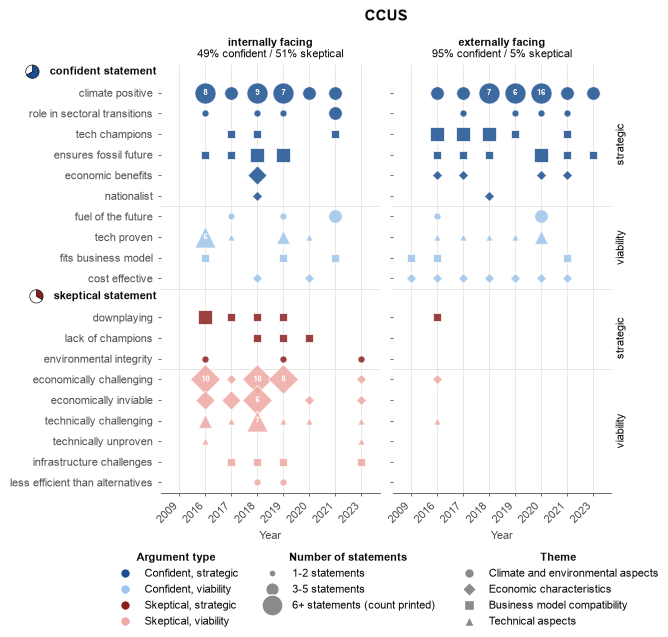

Saved: ccus.png / .pdf


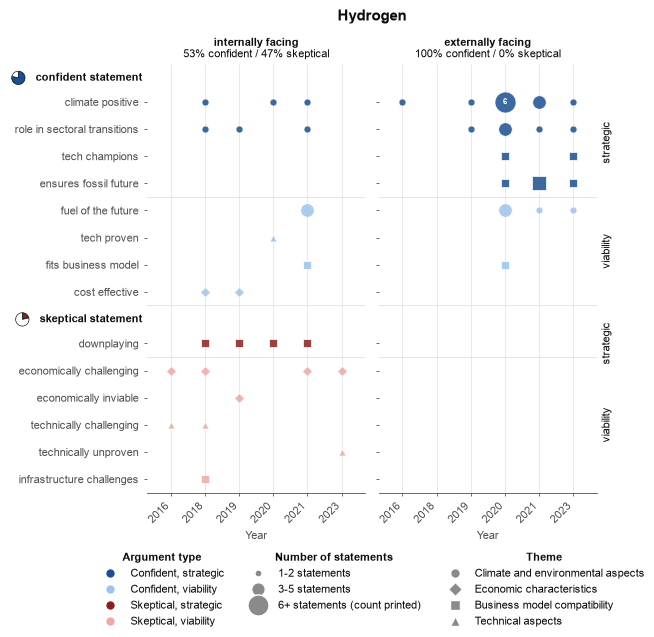

Saved: hydrogen.png / .pdf


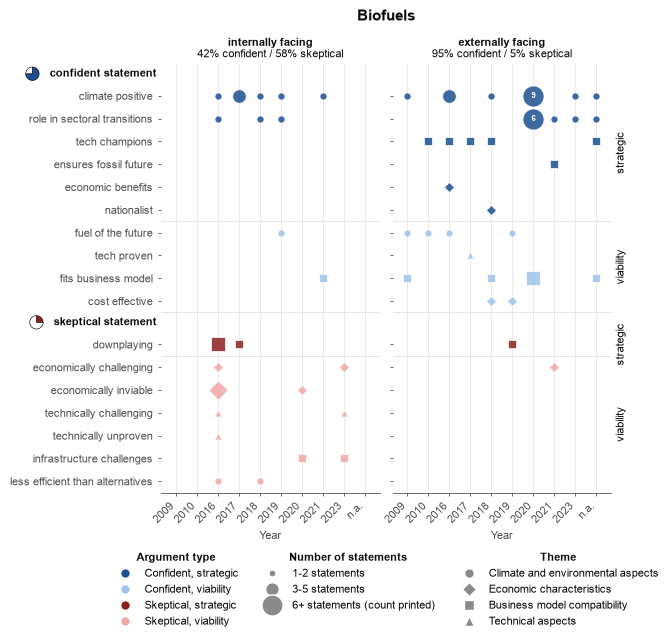

Saved: biofuels.png / .pdf


In [17]:

for TECH in categories:
    SIZE_BINS = [(1, 2, 'small', 26), (3, 5, 'medium', 95), (6, 10 ** 6, 'large', 230)]
    ARG_COLOR = {
        ('confident', 'strategic'): '#1B4F91',
        ('confident', 'viability'): '#9EC4EC',
        ('skeptical', 'strategic'): '#8C1E1E',
        ('skeptical', 'viability'): '#EFA8A4',
    }

    tech_df = bar_df_ny[bar_df_ny['umbrella'] == TECH]
    tech_years = sorted(tech_df['year'].unique(), key=year_sort_key_ny)   # n.a. last
    tech_x = {y: i for i, y in enumerate(tech_years)}
    tech_year_labels = [int(y) if y != 'n.a.' else y for y in tech_years]

    agg = {}
    for audience in ['internal', 'external']:
        audience_df = tech_df[tech_df['audience'] == audience]
        n_confident = (audience_df['statement_class'] == 'confident').sum()
        pct_confident = round(100 * n_confident / len(audience_df)) if len(audience_df) else 0
        agg[audience] = (pct_confident, 100 - pct_confident)

    rows = []
    for stmt_class in ['confident', 'skeptical']:
        for arg_type in ['strategic', 'viability']:
            for category in cat_order_ny[(stmt_class, arg_type)]:
                if ((tech_df['statement_class'] == stmt_class)
                        & (tech_df['statement_category'] == category)).any():
                    rows.append((stmt_class, arg_type, category))

    CLASS_HEADER_GAP = 0.9
    row_y = {}
    y = 0.0
    prev_class = None
    for r in rows:
        if r[0] != prev_class:
            y += CLASS_HEADER_GAP
            prev_class = r[0]
        row_y[r] = y
        y += 1.0
    max_row_y = max(row_y.values())
    total_span = max_row_y + 1.0    # matches y span below

    counts = (tech_df.groupby(['audience', 'statement_class', 'arg_type',
                               'statement_category', 'year']).size())


    def size_of(n):
        for lo, hi, _, s in SIZE_BINS:
            if lo <= n <= hi:
                return s
        return SIZE_BINS[-1][3]


    with plt.rc_context(rc):
        fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(7.5, 6.4),
                                 sharey=True, sharex=True)
        fig.subplots_adjust(left=0.30, right=0.90, top=0.90, bottom=0.23, wspace=0.06)

        for col, audience in enumerate(['internal', 'external']):
            ax = axes[col]

            for (stmt_class, arg_type), grp in pd.Series(row_y).groupby(
                    [pd.Series([r[0] for r in rows]).values,
                     pd.Series([r[1] for r in rows]).values]):
                lo, hi = grp.min() - 0.5, grp.max() + 0.5
                ax.axhline(hi, color=GRID, linewidth=0.6, zorder=1)

            for r in rows:
                for year in tech_years:
                    key = (audience, r[0], r[1], r[2], year)
                    if key not in counts.index:
                        continue
                    n = counts.loc[key]
                    marker = THEME_MARKER[CATEGORY_TO_THEME[r[2]]]
                    ax.scatter(tech_x[year], row_y[r], s=size_of(n), marker=marker,
                               color=ARG_COLOR[(r[0], r[1])], alpha=0.85,
                               edgecolor='white', linewidth=0.6, zorder=3)
                    if n >= SIZE_BINS[-1][0]:      # only large symbols get count
                        ax.text(tech_x[year], row_y[r], f'{n}', ha='center', va='center',
                                fontsize=5.5, fontweight='bold', color='white', zorder=4)

            ax.set_xlim(-0.7, len(tech_years) - 0.3)
            ax.set_ylim(max_row_y + 0.5, -0.5)
            ax.set_xticks(range(len(tech_years)))
            ax.set_xticklabels(tech_year_labels, rotation=45, ha='right')
            ax.set_xlabel('Year', color=INK_MUTED)
            ax.set_yticks([row_y[r] for r in rows])
            ax.set_yticklabels([r[2] for r in rows])
            ax.xaxis.grid(True, color=GRID, linewidth=0.5, zorder=1)
            ax.set_axisbelow(True)
            for side in ['top', 'right', 'left']:
                ax.spines[side].set_visible(False)
            ax.spines['bottom'].set_color(INK_MUTED)
            ax.tick_params(colors=INK_MUTED, length=2.5)
            audience_title = {'internal': 'internally facing', 'external': 'externally facing'}[audience]
            ax.set_title(audience_title, color=INK, fontsize=8, fontweight='bold', pad=13)
            ax.text(0.5, 1.01, f"{agg[audience][0]}% confident / "
                                f"{agg[audience][1]}% skeptical",
                    transform=ax.transAxes, ha='center', va='bottom',
                    fontsize=8, color=INK)

        for (stmt_class, arg_type), grp in pd.Series(row_y).groupby(
                [pd.Series([r[0] for r in rows]).values,
                 pd.Series([r[1] for r in rows]).values]):
            axes[1].annotate(f'{arg_type}',
                             xy=(1.02, 1 - (grp.mean() + 0.5) / total_span),
                             xycoords='axes fraction', ha='left', va='center',
                             rotation=90, fontsize=8, color=INK,
                             clip_on=False, zorder=10)

        # class labels on the left, small pie shows
        # share of all statements in that class
        n_confident_total = int((tech_df['statement_class'] == 'confident').sum())
        n_skeptical_total = int((tech_df['statement_class'] == 'skeptical').sum())
        n_total = n_confident_total + n_skeptical_total

        HEADER_LIFT_PT = 3 * 72 / 25.4   # nudge header up 3mm
        class_annotations = []
        for stmt_class in ['confident', 'skeptical']:
            class_rows = [row_y[r] for r in rows if r[0] == stmt_class]
            if not class_rows:
                continue
            first_row_y = min(class_rows)
            header_y = first_row_y - CLASS_HEADER_GAP / 2
            ann = axes[0].annotate(f'{stmt_class} statement',
                                   xy=(-0.02, header_y),
                                   xycoords=('axes fraction', 'data'),
                                   xytext=(0, HEADER_LIFT_PT), textcoords='offset points',
                                   ha='right', va='center',
                                   fontsize=8, fontweight='bold', color=INK,
                                   clip_on=False, zorder=10)
            class_annotations.append((stmt_class, ann))

        # place pie left of header using rendered text
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        pie_diam_in = 1.5 * 8 / 72.0          # 12pt
        pie_w = pie_diam_in / fig.get_figwidth()
        pie_h = pie_diam_in / fig.get_figheight()
        for stmt_class, ann in class_annotations:
            bbox = ann.get_window_extent(renderer=renderer).transformed(
                fig.transFigure.inverted())
            pie_cx = bbox.x0 - 0.012 - pie_w / 2
            pie_cy = (bbox.y0 + bbox.y1) / 2
            pie_ax = fig.add_axes([pie_cx - pie_w / 2, pie_cy - pie_h / 2,
                                   pie_w, pie_h])
            if stmt_class == 'confident':
                n_this = n_confident_total
                pie_colour = ARG_COLOR[('confident', 'strategic')]
            else:
                n_this = n_skeptical_total
                pie_colour = ARG_COLOR[('skeptical', 'strategic')]
            pie_ax.pie([n_this, n_total - n_this],
                       colors=[pie_colour, 'white'],
                       startangle=90, counterclock=False,
                       wedgeprops=dict(linewidth=0.45, edgecolor='black'))
            pie_ax.set_axis_off()



        colour_handles = [plt.Line2D([], [], marker='o', linestyle='none', markersize=7,
                                     markerfacecolor=ARG_COLOR[(s, a)], markeredgecolor='white',
                                     label=f'{s.capitalize()}, {a}')
                          for s in ['confident', 'skeptical']
                          for a in ['strategic', 'viability']]
        leg1 = fig.legend(handles=colour_handles, loc='upper center',
                          bbox_to_anchor=(0.5, 0.145), frameon=False, fontsize=8,
                          title='Argument type', ncol=1, borderpad=0.0)

        size_handles = [plt.Line2D([], [], marker='o', linestyle='none',
                                   markersize=np.sqrt(s), markerfacecolor='#8a8a88',
                                   markeredgecolor='white',
                                   label=(f'{lo}-{hi} statements' if hi < 10 ** 6
                                          else f'{lo}+ statements (count printed)'))
                        for lo, hi, _, s in SIZE_BINS]
        leg2 = fig.legend(handles=size_handles, loc='upper center',
                          bbox_to_anchor=(0.5, 0.145), frameon=False, fontsize=8,
                          title='Number of statements', ncol=1, borderpad=0.0)

        theme_handles = [plt.Line2D([], [], marker=THEME_MARKER[theme], linestyle='none', markersize=7,
                                    markerfacecolor='#8a8a88', markeredgecolor='white', label=theme)
                         for theme in THEME_CATEGORIES]
        leg3 = fig.legend(handles=theme_handles, loc='upper center',
                          bbox_to_anchor=(0.5, 0.145), frameon=False, fontsize=8,
                          title='Theme', ncol=1, borderpad=0.0)

        for leg in (leg1, leg2, leg3):
            leg.get_title().set_fontweight('bold')
            leg.get_title().set_fontsize(8)
            leg.get_title().set_color(INK)
            for text in leg.get_texts():
                text.set_color(INK)

        TITLE_X = 0.60
        fig.canvas.draw()
        w1 = leg1.get_window_extent().transformed(fig.transFigure.inverted()).width
        w2 = leg2.get_window_extent().transformed(fig.transFigure.inverted()).width
        w3 = leg3.get_window_extent().transformed(fig.transFigure.inverted()).width
        gap = 0.03
        total_w = w1 + gap + w2 + gap + w3
        x1 = TITLE_X - total_w / 2 + w1 / 2
        x2 = x1 + w1 / 2 + gap + w2 / 2
        x3 = x2 + w2 / 2 + gap + w3 / 2
        leg1.set_bbox_to_anchor((x1, 0.145), transform=fig.transFigure)
        leg2.set_bbox_to_anchor((x2, 0.145), transform=fig.transFigure)
        leg3.set_bbox_to_anchor((x3, 0.145), transform=fig.transFigure)

        fig.suptitle(f'{TECH}', fontsize=10.5, fontweight='bold', color=INK,
                     x=TITLE_X, y=0.985)

        fname = f'{TECH.lower()}'
        fig.savefig(f'{fname}.png', dpi=600)
        fig.savefig(f'{fname}.pdf')
        plt.show()
        print(f'Saved: {fname}.png / .pdf')
